# Bindome vs PDB — mixed interface clustering

Cluster 47k designed interfaces and 47k natural interfaces in one run,
then count how many clusters contain both.

**Inputs**

- HumanBindome: `metadata.csv` + `structures/*.tar` (HF `wjulius/HumanBindome`)
- Foldseek-Interface: `pdb_clusters_annotated.tsv` (Zenodo 10.5281/zenodo.22040892)
- PDB assemblies, fetched from RCSB

The Zenodo release ships cluster labels only, no coordinates, so every
natural interface structure is fetched and cut here.

**Protocol** follows `scripts/cluster_pdb.sh` from the foldseek-interface repo,
with one deliberate deviation noted at the representative-rebuild step.

## Setup

In [1]:
import os, re, gzip, json, random, shutil, subprocess, collections
from pathlib import Path

FOLDSEEK  = "/home/wonjun/foldseek/foldseek/bin/foldseek"   # interface build, NOT the one on PATH
BINDOME   = Path("/data/wonjun/HumanBindome")               # raw download
COMPLEXES = Path("/data/wonjun/bindome_iface/full/pdb")     # 306,137 extracted complexes
PDB_TABLE = Path("/data/wonjun/bindome_iface/zenodo/x/pdb_clusters_annotated.tsv")
WORK      = Path("/data/wonjun/repro")

IFACE = ["--distance-threshold", "10", "--min-interface-residues-perchain", "4"]
IF    = " ".join(IFACE)

def run(*args, **kw):
    """Run foldseek. Raises on non-zero exit."""
    return subprocess.run([FOLDSEEK, *map(str, args)], text=True,
                          capture_output=True, check=True, **kw).stdout

version = run("version").strip()
assert version == "463739e0014a1549a527de589102cde98f802f37", f"wrong build: {version}"
assert (BINDOME/"metadata.csv").exists()
assert len(os.listdir(COMPLEXES)) == 306137
assert PDB_TABLE.exists()
WORK.mkdir(parents=True, exist_ok=True)

print("foldseek ", version[:8])
print("complexes", f"{len(os.listdir(COMPLEXES)):,}")
print("pdb table", f"{PDB_TABLE.stat().st_size/1e9:.2f} GB")

foldseek  463739e0
complexes 306,137
pdb table 1.36 GB


## 1. Chain and dimer DBs

`createdb` reads a directory of structures, so the complexes must be flat.
Each is two chains, hence a chain index twice the dimer count.

~90 s, 1.6 GB.

In [ ]:
db  = WORK/"db"
tmp = WORK/"tmp"
db.mkdir(parents=True, exist_ok=True)
tmp.mkdir(exist_ok=True)

run("createdb", COMPLEXES, db/"chains", "--threads", 32, "-v", 1)
print("chains:", sum(1 for _ in open(db/"chains.index")))

run("createdimerdb", db/"chains", db/"dimers", tmp, *IFACE, "--threads", 32, "-v", 1)
print("dimers:", sum(1 for _ in open(db/"dimers.index")) // 2)

```
chains: 612274
dimers: 306137
```

## 2. Dedup at TM 0.9

Sister ProteinMPNN variants off the same seed share a backbone, so they are
redundant. TM 0.9 is strict, so genuinely distinct interfaces never merge.

No `--exhaustive-search` here — that flag is what makes the final clustering
expensive, and skipping it is the only reason 306,137 dimers is tractable.

**160 min, ~107 GB RAM, ~130 GB scratch.**

In [ ]:
!{FOLDSEEK} multimercluster {db}/dimers {WORK}/dedup {WORK}/tmp_dedup \
     --multimer-tm-threshold 0.9 \
     --chain-tm-threshold 0.5 \
     --interface-lddt-threshold 0 \
     -c 0 --cov-mode 0 --cluster-mode 0 \
     --threads 48 -v 1

`multimercluster` writes a DB, not a table. Convert it — 0.6 s.

In [ ]:
!{FOLDSEEK} createtsv {db}/dimers {db}/dimers {WORK}/dedup {WORK}/dedup_cluster.tsv \
     --threads 16 -v 1

In [ ]:
members = collections.defaultdict(list)
for line in open(WORK/"dedup_cluster.tsv"):
    rep, member = line.split()
    members[rep].append(member)

print(f"designs         {sum(len(v) for v in members.values()):,}")
print(f"representatives {len(members):,}")

```
designs         306,137
representatives 188,710
```

62% retention. Collapse to a few thousand would mean the thresholds are not
being applied; retaining all 306,137 would mean the clustering no-op'd.

## 3. Representative interfaces

Rebuild from the representatives' **source PDBs**, not with `createsubdb` on
the cluster DB.

The authors' `cluster_pdb.sh` uses `createsubdb clu PDB_dimer PDB_dimer_reps`.
On this foldseek build that selects at cluster-key granularity (188,710 entries
where a dimer DB needs 377,420) and carries the parent's `.lookup` over stale,
so `createinterfacedb` then yields **35,712 interfaces instead of 188,710** —
exit code 0, no warning. Verified on this data.

~35 s.

In [ ]:
# Representative names carry a chain suffix: "<design>_A_B". Strip it to get
# back to the source filename.
reps = {line.split("\t")[0].rsplit("_", 2)[0] for line in open(WORK/"dedup_cluster.tsv")}
(WORK/"reps").mkdir(exist_ok=True)
for d in reps:
    link = WORK/"reps"/f"{d}.pdb"
    if not link.exists():
        link.symlink_to(COMPLEXES/f"{d}.pdb")

print(f"representatives linked: {len(os.listdir(WORK/'reps')):,}")

In [ ]:
!{FOLDSEEK} createdb          {WORK}/reps      {WORK}/rep       --threads 48 -v 1
!{FOLDSEEK} createdimerdb     {WORK}/rep       {WORK}/rep_dimer {WORK}/tmp {IF} --threads 48 -v 1
!{FOLDSEEK} createinterfacedb {WORK}/rep_dimer {WORK}/rep_int   {IF} -v 1

n = sum(1 for _ in open(WORK/"rep_int.index")) // 2
print(f"interfaces: {n:,}")
assert n == 188710, f"chains were dropped — got {n}"

```
interfaces: 188,710
targets covered: 8,296
```

## 4. Sample 47,178 per side

- **Bindome** — uniform over the 188,710 representatives.
  `sorted()` matters: `reps` is a set and set order varies between runs, so
  without it the seeded draw would not be reproducible.
- **PDB** — uniform over rows with `dimerrep == 1`, the frame the authors fed
  to their own interface clustering. That is the same point in the pipeline the
  Bindome side reached after the TM 0.9 dedup; sampling raw rows would pit
  deduplicated designs against undeduplicated PDB.

47,178 is 25.0% of one side and 24.9% of the other. No centroid re-weighting —
a uniform draw lands at 40.7% centroids, which is the PDB's real composition
at this level.

~1 min (1.36 GB line scan).

In [ ]:
N, SEED = 47178, 20260915

bindome = random.Random(SEED).sample(sorted(reps), N)

pdb = []
with open(PDB_TABLE) as fh:
    next(fh)
    for line in fh:
        f = line.rstrip("\n").split("\t")
        if f[7] == "1":                                   # dimerrep
            pdb.append((f[2], f[1], f[3], f[6], f[8]))    # asm, chain0, chain1, intcluster, intrep
print(f"pdb representatives available: {len(pdb):,}")

pdb = random.Random(SEED).sample(pdb, N)
centroids = sum(1 for r in pdb if r[4] == "1")
print(f"sampled {N:,} per side  ({100*centroids/N:.1f}% centroids)")

(WORK/"pick_bindome.txt").write_text("\n".join(bindome) + "\n")
(WORK/"pick_pdb.tsv").write_text("".join("\t".join(r[:4]) + "\n" for r in pdb))

```
pdb representatives available: 189,830
sampled 47,178 per side  (40.7% centroids)
```

## 5. Fetch the assemblies

The Zenodo table has labels only, so every PDB-side structure comes from RCSB.
47,178 rows resolve to ~23k distinct files (one entry can back dozens of pairs).

~17 min, 15 GB. Skips what is already present.

In [ ]:
import urllib.request, concurrent.futures

(WORK/"cif").mkdir(exist_ok=True)
needed  = sorted({r[0] for r in pdb})
missing = [a for a in needed if not (WORK/"cif"/f"{a}.cif.gz").exists()]
print(f"{len(needed):,} assemblies needed, {len(missing):,} to fetch")

def fetch(asm):
    out = WORK/"cif"/f"{asm}.cif.gz"
    tmp = out.with_suffix(".part")
    try:
        urllib.request.urlretrieve(f"https://files.rcsb.org/download/{asm}.cif.gz", tmp)
        with gzip.open(tmp) as fh: fh.read(1)   # truncated transfers still return 200
        tmp.rename(out)
    except Exception as e:
        tmp.unlink(missing_ok=True)
        return f"{asm}\t{e}"

with concurrent.futures.ThreadPoolExecutor(16) as ex:
    failed = [r for r in ex.map(fetch, missing) if r]

# A few 404s are expected: ids in the 2025 table that RCSB no longer serves.
(WORK/"fetch_failed.txt").write_text("\n".join(failed))
print(f"fetched {len(missing)-len(failed):,}, failed {len(failed)}")

```
23,274 assemblies needed, 23,274 to fetch
fetched 23,262, failed 12
```

## 6. Stage the mixed pool

- **PDB** → `W<row>C<intcluster>.cif`, the two named chains cut from the assembly
- **Bindome** → copied in as-is

The leading `W` is how the readout tells the two apart; Bindome names always
contain `no_hotspot`. Copies, not symlinks, so `pool/` depends on nothing
outside `WORK`.

~35 min, ~30 GB.

In [ ]:
(WORK/"pool").mkdir(exist_ok=True)

def atom_site(path):
    """Return (header lines, atom rows, index of auth_asym_id)."""
    header, rows, inside = [], [], False
    with gzip.open(path, "rt", errors="replace") as fh:
        for line in fh:
            if line.startswith("_atom_site."):
                header.append(line.rstrip("\n")); inside = True; continue
            if inside:
                if line.startswith(("#", "loop_", "_", "data_")): break
                if line.strip(): rows.append(line)
    if not header: return None, None, None
    names = [h.split(".", 1)[1].strip() for h in header]   # column order varies per entry
    if "auth_asym_id" not in names: return None, None, None
    return header, rows, names.index("auth_asym_id")

wanted = collections.defaultdict(list)
for n, (asm, c0, c1, clu, _) in enumerate(pdb, 1):
    wanted[asm].append((n, c0, c1, clu))

done = fail = 0
for asm, entries in wanted.items():          # one open per assembly, not per entry
    src = WORK/"cif"/f"{asm}.cif.gz"
    if not src.exists():
        fail += len(entries); continue
    header, rows, chain_col = atom_site(src)
    if header is None:
        fail += len(entries); continue
    by_chain = collections.defaultdict(list)
    for r in rows:
        parts = r.split()
        if len(parts) > chain_col:
            by_chain[parts[chain_col]].append(r)
    for n, c0, c1, clu in entries:
        a, b = by_chain.get(c0), by_chain.get(c1)
        if not a or not b:                   # chain absent from the deposited file
            fail += 1; continue
        name = f"W{n}C{clu}"
        with open(WORK/"pool"/f"{name}.cif", "w") as w:
            w.write(f"data_{name}\n#\nloop_\n")
            w.write("\n".join(header) + "\n")
            w.writelines(a); w.writelines(b); w.write("#\n")
        done += 1

for d in bindome:
    dst = WORK/"pool"/f"{d}.pdb"
    if not dst.exists():
        shutil.copy(WORK/"reps"/f"{d}.pdb", dst)

assert not [p for p in (WORK/"pool").iterdir() if p.is_symlink()]
print(f"pdb extracted {done:,}, failed {fail:,}")
print(f"pool: {len(list((WORK/'pool').glob('*.pdb'))):,} bindome "
      f"+ {len(list((WORK/'pool').glob('*.cif'))):,} pdb")

## 7. Interface DB

`createinterfacedb` keeps only contact residues (Cα within 10 Å, ≥4 per chain),
concatenates the two chains and recomputes 3Di — so what gets clustered is the
interface, not the parent complex (~35 residues vs ~136).

~31 s.

In [ ]:
!{FOLDSEEK} createdb          {WORK}/pool      {WORK}/pooldb    --threads 48 -v 1
!{FOLDSEEK} createdimerdb     {WORK}/pooldb    {WORK}/pooldimer {WORK}/tmp {IF} --threads 48 -v 1
!{FOLDSEEK} createinterfacedb {WORK}/pooldimer {WORK}/int       {IF} -v 1

print("interfaces:", sum(1 for _ in open(WORK/"int.index")) // 2)

## 8. Cluster at TM 0.4

The authors' stage-2 flag set: exhaustive (no prefilter), TM 0.4, greedy set
cover (`--cluster-mode 0`), single pass.

Launched detached — `start_new_session=True` gives it no controlling terminal,
so it survives kernel restart and network loss. A `!` cell with a trailing `&`
does not work: IPython refuses background processes.

**Several hours, ~580 GB scratch in `tmpc/`.** That scratch is only auto-removed
on success; delete it by hand if the run is interrupted.

In [ ]:
cmd = [FOLDSEEK, "easy-multimercluster", f"{WORK}/int", f"{WORK}/clu", f"{WORK}/tmpc",
       "--exhaustive-search", "1", "-e", "10000000", "--lddt-threshold", "0.20",
       "--chain-tm-threshold", "0", "-c", "0", "--interface-lddt-threshold", "0",
       "--cov-mode", "0", "--cluster-mode", "0", "--max-iterations", "1",
       "--multimer-tm-threshold", "0.4",
       "--threads", "48", "--split-memory-limit", "64G", "-v", "1"]

(WORK/"logs").mkdir(exist_ok=True)
log = open(WORK/"logs/cluster.log", "w")
p = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT,
                     start_new_session=True)
print("pid", p.pid)

In [ ]:
# poll
!pgrep -af easy-multimercluster | grep -v grep
!du -sh {WORK}/tmpc
!ls -la {WORK}/clu_cluster.tsv 2>/dev/null

## 9. Count

Per cluster: pure Bindome, pure PDB, or mixed. `^W\d+C\d+_` identifies PDB.

Denominators come from the clustering output, not from `N`, so structures lost
to 404s and missing chains are excluded rather than counted as failures.

In [2]:
members = collections.defaultdict(list)
for line in open(WORK/"clu_cluster.tsv"):
    rep, member = line.rstrip("\n").split("\t")
    members[rep].append(member)

is_pdb = re.compile(r"^W\d+C\d+_").match
kind = collections.Counter()
bd_total = pdb_total = bd_mixed = pdb_mixed = 0

for group in members.values():
    p = sum(1 for m in group if is_pdb(m))
    b = len(group) - p
    bd_total += b; pdb_total += p
    label = "mixed" if (p and b) else ("pure PDB" if p else "pure Bindome")
    kind[label] += 1
    if label == "mixed":
        bd_mixed += b; pdb_mixed += p

K, n = len(members), sum(len(g) for g in members.values())
print(f"interfaces   {n:,}   ({bd_total:,} Bindome + {pdb_total:,} PDB)")
print(f"clusters K   {K:,}   K/n {K/n:.4f}\n")
for label in ("pure Bindome", "pure PDB", "mixed"):
    print(f"  {label:<14}{kind[label]:>8,}  {100*kind[label]/K:>5.1f}%")
print(f"\nBindome sharing a cluster with PDB: {bd_mixed:,} ({100*bd_mixed/bd_total:.2f}%)")
print(f"PDB sharing a cluster with Bindome: {pdb_mixed:,} ({100*pdb_mixed/pdb_total:.2f}%)")

interfaces   94,286   (47,178 Bindome + 47,108 PDB)
clusters K   58,614   K/n 0.6217

  pure Bindome    31,930   54.5%
  pure PDB        26,149   44.6%
  mixed              535    0.9%

Bindome sharing a cluster with PDB: 1,684 (3.57%)
PDB sharing a cluster with Bindome: 1,664 (3.53%)


## Result

```
interfaces   94,286   (47,178 Bindome + 47,108 PDB)
clusters K   58,614   K/n 0.6217

  pure Bindome    31,930   54.5%
  pure PDB        26,149   44.6%
  mixed              535    0.9%

Bindome sharing a cluster with PDB: 1,684 (3.57%)
PDB sharing a cluster with Bindome: 1,664 (3.53%)
```

**96.4% of designed interfaces sit in a cluster containing no PDB interface.**

Against the September run of the same protocol: 94,289 interfaces, 58,770
clusters, 511 mixed, 3.24%. The 3 missing interfaces are `1bwn-assembly2`,
withdrawn from RCSB since. The 0.33 pp difference on the headline number is
greedy set cover being order-dependent — which structure becomes a centroid
shifts between runs.

A pairwise search of the same two sets found 15.97% of designs with
qTM ≥ 0.4 to some PDB interface. Clustering gives 3.57%, and the gap is not a
contradiction: membership requires a direct edge to the **centroid**, never a
transitive one, so clearing the threshold against some PDB interface does not
place a design in its cluster.

---
# Cluster statistics

Everything below reads `clu_cluster.tsv` into one DataFrame called `clusters`.
Poke at that; the helpers are thin wrappers over it.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

PDB_RE = re.compile(r"^W(\d+)C(\d+)_")      # PDB member: W<row>C<intcluster>_<c0>_<c1>
BD_RE  = re.compile(r"^(\w+)_DOMAIN(\d+)-")  # Bindome member: <uniprot>_DOMAIN<k>-...

members = collections.defaultdict(list)
for line in open(WORK/"clu_cluster.tsv"):
    rep, m = line.rstrip("\n").split("\t")
    members[rep].append(m)

rows = []
for rep, grp in members.items():
    p = [m for m in grp if PDB_RE.match(m)]
    b = [m for m in grp if not PDB_RE.match(m)]
    rows.append(dict(
        rep          = rep,
        n            = len(grp),
        n_bd         = len(b),
        n_pdb        = len(p),
        kind         = "mixed" if (p and b) else ("pdb" if p else "bindome"),
        frac_bd      = len(b) / len(grp),
        rep_is_pdb   = bool(PDB_RE.match(rep)),
        pdb_clusters = sorted({PDB_RE.match(m).group(2) for m in p}),
        bd_targets   = sorted({BD_RE.match(m).group(1) for m in b if BD_RE.match(m)}),
    ))

clusters = pd.DataFrame(rows).set_index("rep").sort_values("n", ascending=False)

def show(rep, limit=20):
    """Print one cluster's members, PDB first."""
    grp = sorted(members[rep], key=lambda m: not PDB_RE.match(m))
    print(f"{rep}   n={len(grp)}   {clusters.loc[rep, 'kind']}")
    for m in grp[:limit]:
        print("   ", "PDB " if PDB_RE.match(m) else "BD  ", m)
    if len(grp) > limit:
        print(f"    ... {len(grp)-limit} more")

mixed   = clusters[clusters.kind == "mixed"]
bindome_only = clusters[clusters.kind == "bindome"]
pdb_only     = clusters[clusters.kind == "pdb"]

print(clusters.kind.value_counts().to_string())
print(f"\n{len(clusters):,} clusters over {clusters.n.sum():,} interfaces")

kind
bindome    31930
pdb        26149
mixed        535

58,614 clusters over 94,286 interfaces


## Size and composition

In [ ]:
print("size by kind")
print(clusters.groupby("kind").n.agg(["count", "mean", "median", "max"]).round(2).to_string())

print(f"\nsingletons: {(clusters.n == 1).sum():,}  ({100*(clusters.n == 1).mean():.1f}%)")
print(f"largest:    {clusters.n.max():,}")

print("\nclusters with >=5 members")
print(clusters[clusters.n >= 5].kind.value_counts().to_string())

bd, pd_ = clusters.n_bd.sum(), clusters.n_pdb.sum()
print(f"\nBindome in a mixed cluster: {mixed.n_bd.sum():,} / {bd:,} "
      f"({100*mixed.n_bd.sum()/bd:.2f}%)")
print(f"PDB in a mixed cluster:     {mixed.n_pdb.sum():,} / {pd_:,} "
      f"({100*mixed.n_pdb.sum()/pd_:.2f}%)")

```
size by kind
         count  mean  median   max
bindome  31930  1.42     1.0    73
mixed      535  6.26     4.0   108
pdb      26149  1.74     1.0  2056

singletons: 46,084  (78.6%)
clusters with >=5 members:  pdb 917, bindome 776, mixed 241
```

Mixed clusters are ~4x larger than pure ones, which is expected: a cluster has
to be big before it has room to contain both.

## Plots

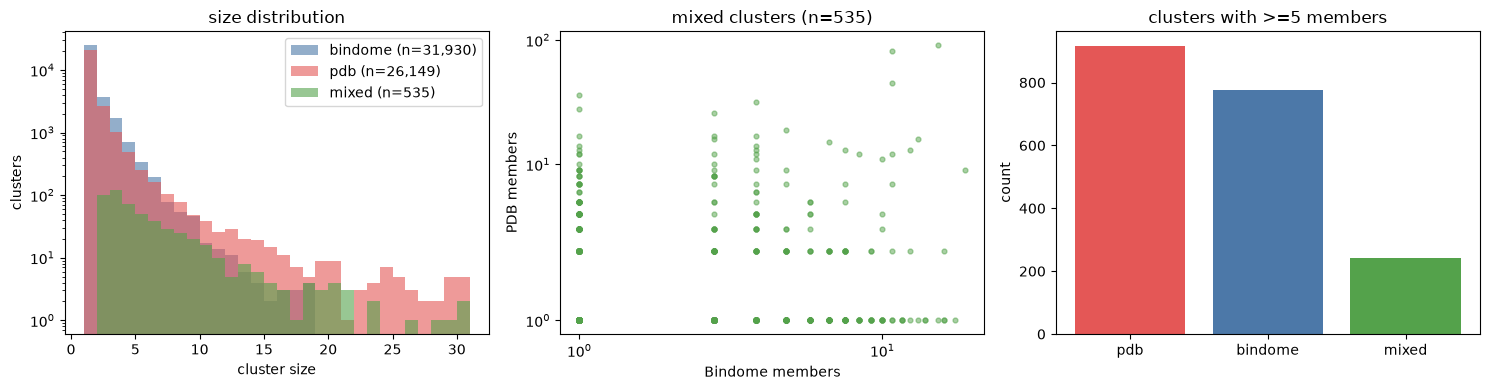

In [5]:
import numpy as np

COL  = {"bindome": "#4C78A8", "pdb": "#E45756", "mixed": "#54A24B"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# --- size distribution, as lines: overlapping bars were unreadable ---
bins = np.arange(1, 41)
for k, c in COL.items():
    s = clusters[clusters.kind == k].n
    h, _ = np.histogram(s, bins=bins)
    ax[0].plot(bins[:-1], h, color=c, lw=1.8, marker="o", ms=3,
               label=f"{k} (n={len(s):,})")
ax[0].set_yscale("log")
ax[0].set_xlabel("cluster size"); ax[0].set_ylabel("clusters")
ax[0].set_title("size distribution"); ax[0].legend(frameon=False); ax[0].grid(alpha=.2)

# --- same data ranked: shows the tail without binning artefacts ---
for k, c in COL.items():
    s = np.sort(clusters[clusters.kind == k].n)[::-1]
    ax[1].plot(np.arange(1, len(s)+1) / len(s) * 100, s, color=c, lw=1.8, label=k)
ax[1].set_yscale("log")
ax[1].set_xlabel("% of clusters (largest first)"); ax[1].set_ylabel("cluster size")
ax[1].set_title("size, ranked"); ax[1].legend(frameon=False); ax[1].grid(alpha=.2)

# --- composition of the mixed clusters; dashed line is 1:1 ---
ax[2].scatter(mixed.n_bd, mixed.n_pdb, s=14, alpha=.45,
              color=COL["mixed"], edgecolor="none")
lim = max(mixed.n_bd.max(), mixed.n_pdb.max()) * 1.2
ax[2].plot([0, lim], [0, lim], ls="--", lw=1, color="#888")
ax[2].set_xscale("symlog"); ax[2].set_yscale("symlog")
ax[2].set_xlabel("Bindome members"); ax[2].set_ylabel("PDB members")
ax[2].set_title(f"mixed clusters (n={len(mixed):,})"); ax[2].grid(alpha=.2)

plt.tight_layout(); plt.show()

## Which natural interfaces do designs reach?

Each mixed cluster carries the `intcluster` ids of its PDB members. If designs
were hitting natural interface space broadly these would be spread thin; a few
ids recurring means designs converge on a handful of common geometries.

In [ ]:
recur = collections.Counter(c for lst in mixed.pdb_clusters for c in lst)
print(f"{len(recur):,} distinct PDB interface clusters appear in a mixed cluster")
print(f"out of {len({c for lst in clusters.pdb_clusters for c in lst}):,} present in the pool\n")
for c, k in recur.most_common(10):
    print(f"  IC{c:<8} in {k:>3} mixed clusters")

```
IC249     in  50 mixed clusters
IC67573   in  38
IC70624   in  33
IC37560   in  22
IC72802   in  19
```

## Handles

```python
clusters                            # the DataFrame — one row per cluster
clusters.loc["W46042C249_Z_e"]      # one cluster's row
show("W46042C249_Z_e")              # print its members

mixed.head(10)                      # biggest mixed clusters
mixed[mixed.n_bd > 10]              # mixed clusters with many designs
clusters[clusters.n >= 50]          # the big ones
clusters[clusters.frac_bd > 0.9]    # design-dominated
bindome_only.n.max()                # largest all-design cluster

members["W46042C249_Z_e"]           # raw member list
```

Columns: `n`, `n_bd`, `n_pdb`, `kind`, `frac_bd`, `rep_is_pdb`,
`pdb_clusters`, `bd_targets`.

In [ ]:
# the largest mixed clusters
mixed.head(10)[["n", "n_bd", "n_pdb", "frac_bd"]]

In [ ]:
show(mixed.index[0])